In [1]:
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [2]:
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Saving amazon.csv to amazon.csv
Dataset shape: (1465, 16)

Column names:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [3]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Check essential columns
required_cols = ["rating", "review_title", "review_content"]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(
        f"Missing columns: {missing_cols}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# Convert rating to numeric
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

# Keep valid ratings from 1 to 5
df = df.dropna(subset=["rating"])
df = df[df["rating"].between(1, 5)].copy()

# Convert prices and rating count into numeric values
numeric_candidates = [
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating_count"
]

for col in numeric_candidates:
    if col not in df.columns:
        df[col] = np.nan

    if col in ["discounted_price", "actual_price", "rating_count"]:
        df[col] = (
            df[col].astype(str)
            .str.replace(r"[₹$,\s]", "", regex=True)
        )
    else:
        df[col] = (
            df[col].astype(str)
            .str.replace("%", "", regex=False)
            .str.strip()
        )

    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)

# Fill missing text values
text_cols = [
    "product_name", "category", "about_product",
    "review_title", "review_content"
]

for col in text_cols:
    if col not in df.columns:
        df[col] = ""
    df[col] = df[col].fillna("").astype(str).str.strip()

print("Cleaned dataset shape:", df.shape)
print("\nMissing values after text cleaning:")
print(df[text_cols].isnull().sum())

display(df.head())


Missing values before cleaning:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

Duplicate rows: 0
Cleaned dataset shape: (1464, 16)

Missing values after text cleaning:
product_name      0
category          0
about_product     0
review_title      0
review_content    0
dtype: int64


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43,4.0,43994.0,"Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 1464 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1464 non-null   object 
 1   product_name         1464 non-null   object 
 2   category             1464 non-null   object 
 3   discounted_price     1464 non-null   float64
 4   actual_price         1464 non-null   float64
 5   discount_percentage  1464 non-null   int64  
 6   rating               1464 non-null   float64
 7   rating_count         1462 non-null   float64
 8   about_product        1464 non-null   object 
 9   user_id              1464 non-null   object 
 10  user_name            1464 non-null   object 
 11  review_id            1464 non-null   object 
 12  review_title         1464 non-null   object 
 13  review_content       1464 non-null   object 
 14  img_link             1464 non-null   object 
 15  product_link         1

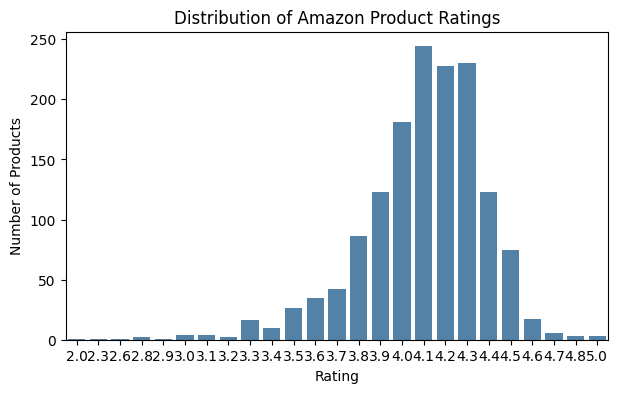

In [4]:
print("Dataset information:")
df.info()

print("\nRating statistics:")
print(df["rating"].describe())

print("\nRating distribution:")
print(df["rating"].value_counts().sort_index())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="rating", color="steelblue")
plt.title("Distribution of Amazon Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

In [5]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()


df["review_text"] = (
    df["review_title"] + " " +
    df["review_content"] + " " +
    df["product_name"] + " " +
    df["about_product"]
).apply(clean_text)

# Handle blank categories
df["category"] = df["category"].replace("", "Unknown")

# Numeric features used by the model
numeric_cols = [
    "discounted_price",
    "actual_price",
    "discount_percentage"
]

print("Example processed review:")
print(df["review_text"].iloc[0][:500])

print("\nProduct features:")
print(numeric_cols)

Example processed review:
satisfied,charging is really fast,value for money,product review,good quality,good product,good product,as of now seems good looks durable charging is fine toono complains,charging is really fast, good product.,till now satisfied with the quality.,this is a good product . the charging speed is slower than the original iphone cable,good quality, would recommend, had worked well till date and was having no issue.cable is also sturdy enough...have asked for replacement and company is doing the same

Product features:
['discounted_price', 'actual_price', 'discount_percentage']


In [6]:
X_text = df["review_text"].to_numpy(dtype=str)
X_category = df["category"].to_numpy(dtype=str)
X_num = df[numeric_cols].to_numpy(dtype="float32")
y = df["rating"].to_numpy(dtype="float32")

# First separate the final test set
all_idx = np.arange(len(df))

train_val_idx, test_idx = train_test_split(
    all_idx,
    test_size=0.15,
    random_state=42
)

# Split remaining records into training and validation
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.15 / 0.85,
    random_state=42
)

text_train, text_val, text_test = (
    X_text[train_idx],
    X_text[val_idx],
    X_text[test_idx]
)

cat_train, cat_val, cat_test = (
    X_category[train_idx],
    X_category[val_idx],
    X_category[test_idx]
)

num_train_raw = X_num[train_idx]
num_val_raw = X_num[val_idx]
num_test_raw = X_num[test_idx]

y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

print("Training records:", len(train_idx))
print("Validation records:", len(val_idx))
print("Testing records:", len(test_idx))

Training records: 1024
Validation records: 220
Testing records: 220


In [7]:
medians = np.nanmedian(num_train_raw, axis=0)
medians = np.where(np.isfinite(medians), medians, 0.0)

def impute_numeric(data):
    return np.where(np.isfinite(data), data, medians).astype("float32")

num_train_clean = impute_numeric(num_train_raw)
num_val_clean = impute_numeric(num_val_raw)
num_test_clean = impute_numeric(num_test_raw)

# Normalize features
scaler = StandardScaler()

num_train = scaler.fit_transform(num_train_clean).astype("float32")
num_val = scaler.transform(num_val_clean).astype("float32")
num_test = scaler.transform(num_test_clean).astype("float32")

print("Normalized training features:")
print(num_train[:5])

Normalized training features:
[[-0.16899346  0.20734397  1.2328901 ]
 [-0.42013595 -0.4542833   0.5915492 ]
 [-0.3638934  -0.38362494  0.27087882]
 [-0.42514765 -0.4631156   0.5457392 ]
 [ 3.8669662   3.916908   -0.46208215]]


In [8]:
MAX_TOKENS = 10000
SEQUENCE_LENGTH = 150

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation"
)

# Learn vocabulary only from training text
vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(text_train).batch(32)
)

vocab_size = len(vectorizer.get_vocabulary())

print("Vocabulary size:", vocab_size)
print("\nOriginal review:")
print(text_train[0][:200])

print("\nEncoded numerical sequence:")
print(vectorizer(tf.constant([text_train[0]])).numpy()[0][:40])

Vocabulary size: 10000

Original review:
not polished enough. (improving with updates),best for the budget 👍,value of money,nice product,good product,super value for money,awesome product,product itv [update: sept 29] boat seems to have hear

Encoded numerical sequence:
[  15 2806  261 6101    9 6788    6    2  237 4249   10 2145  227 3626
  138    6 7400 1444 7547  349 4382 4232  233  474    5   28 2688    2
 1762 6606    3 2493    2   53  379  117   93   31    7  222]


In [9]:
category_lookup = tf.keras.layers.StringLookup(
    output_mode="one_hot",
    num_oov_indices=1
)

category_lookup.adapt(
    tf.data.Dataset.from_tensor_slices(cat_train).batch(32)
)

print("Category vocabulary:")
print(category_lookup.get_vocabulary()[:20])

Category vocabulary:
['[UNK]', np.str_('Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables'), np.str_('Electronics|WearableTechnology|SmartWatches'), np.str_('Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones'), np.str_('Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions'), np.str_('Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear'), np.str_('Electronics|HomeTheater,TV&Video|Accessories|RemoteControls'), np.str_('Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice'), np.str_('Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables'), np.str_('Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|Irons|DryIrons'), np.str_('Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders'), np.str_('Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|LintShavers'), np.str_('Home&Kitchen|Heating,Cooling&AirQu

In [10]:
tf.keras.utils.set_random_seed(42)

# Input 1: review text
text_input = tf.keras.Input(
    shape=(),
    dtype=tf.string,
    name="review"
)

tokens = vectorizer(text_input)

x1 = tf.keras.layers.Embedding(
    input_dim=vocab_size,
    output_dim=64,
    mask_zero=True
)(tokens)

x1 = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(32)
)(x1)

x1 = tf.keras.layers.Dropout(0.3)(x1)

# Input 2: normalized numeric features
numeric_input = tf.keras.Input(
    shape=(len(numeric_cols),),
    dtype=tf.float32,
    name="numeric"
)

x2 = tf.keras.layers.Dense(
    16,
    activation="relu"
)(numeric_input)

# Input 3: product category
category_input = tf.keras.Input(
    shape=(),
    dtype=tf.string,
    name="category"
)

x3 = category_lookup(category_input)

# Combine all features
combined = tf.keras.layers.Concatenate()([x1, x2, x3])

combined = tf.keras.layers.Dense(
    64,
    activation="relu"
)(combined)

combined = tf.keras.layers.Dropout(0.3)(combined)

combined = tf.keras.layers.Dense(
    32,
    activation="relu"
)(combined)

# Regression output
output = tf.keras.layers.Dense(
    1,
    activation="linear",
    name="predicted_rating"
)(combined)

model = tf.keras.Model(
    inputs={
        "review": text_input,
        "numeric": numeric_input,
        "category": category_input
    },
    outputs=output
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 150)       │          0 │ review[0][0]      │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 64)   │    640,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     24,832 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │         64 │ numeric[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ string_lookup_1     │ (None, 185)       │          0 │ category[0][0]    │
│ (StringLookup)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 265)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dense[0][0],      │
│                     │                   │            │ string_lookup_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │     17,024 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predicted_rating    │ (None, 1)         │         33 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 684,033 (2.61 MB)

 Trainable params: 684,033 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
X_train = {
    "review": tf.constant(text_train, dtype=tf.string),
    "numeric": tf.constant(num_train, dtype=tf.float32),
    "category": tf.constant(cat_train, dtype=tf.string)
}

X_val = {
    "review": tf.constant(text_val, dtype=tf.string),
    "numeric": tf.constant(num_val, dtype=tf.float32),
    "category": tf.constant(cat_val, dtype=tf.string)
}

X_test = {
    "review": tf.constant(text_test, dtype=tf.string),
    "numeric": tf.constant(num_test, dtype=tf.float32),
    "category": tf.constant(cat_test, dtype=tf.string)
}

# Define a custom regression accuracy: % of predictions within 0.5 stars of true value
def rating_accuracy(y_true, y_pred):
    diff = tf.abs(y_true - y_pred)
    return tf.reduce_mean(tf.cast(diff <= 0.5, tf.float32))

# Re-compile model with the custom accuracy metric
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae", rating_accuracy]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 146ms/step - loss: 0.2206 - mae: 0.3724 - rating_accuracy: 0.6245 - val_loss: 0.1793 - val_mae: 0.3672 - val_rating_accuracy: 0.6849
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - loss: 0.1874 - mae: 0.3444 - rating_accuracy: 0.6375 - val_loss: 0.1780 - val_mae: 0.3661 - val_rating_accuracy: 0.6845
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - loss: 0.1653 - mae: 0.3304 - rating_accuracy: 0.6468 - val_loss: 0.1450 - val_mae: 0.3187 - val_rating_accuracy: 0.7494
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - loss: 0.1595 - mae: 0.3175 - rating_accuracy: 0.6426 - val_loss: 0.2673 - val_mae: 0.4651 - val_rating_accuracy: 0.5390
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - loss: 0.1600 - mae: 0.3219 - rating_accuracy: 0.6599 - val_loss: 0.1992 - val_mae: 0.3896 - val_rating_accuracy: 0.6542
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - loss: 0.1553 - mae: 0.3185 - rating_accuracy: 0.6489 - val_loss: 0.1010 - val_ma

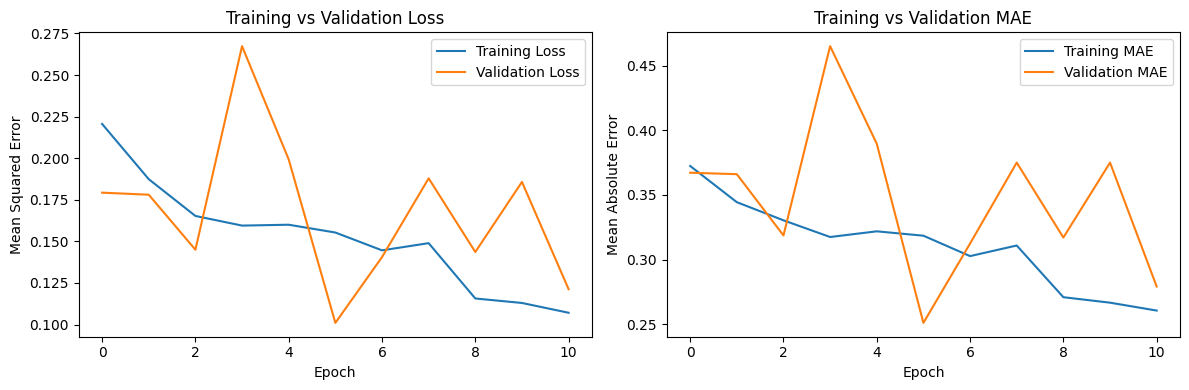

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.title("Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
# Predict ratings
y_pred = model.predict(X_test, verbose=0).flatten()

# Limit predictions to the valid rating range
y_pred = np.clip(y_pred, 1, 5)

# Convert predictions to whole stars for comparison
y_pred_stars = np.clip(np.rint(y_pred), 1, 5).astype(int)
y_actual_stars = np.rint(y_test).astype(int)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
accuracy = accuracy_score(y_actual_stars, y_pred_stars)

print("MODEL EVALUATION")
print("----------------")
print(f"MAE: {mae:.4f} stars")
print(f"RMSE: {rmse:.4f} stars")
print(f"R2 Score: {r2:.4f}")
print(f"Rounded-star accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_actual_stars,
    y_pred_stars,
    labels=[1, 2, 3, 4, 5],
    zero_division=0
))

MODEL EVALUATION
----------------
MAE: 0.2161 stars
RMSE: 0.2801 stars
R2 Score: 0.0078
Rounded-star accuracy: 95.91%

Classification Report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         0
           2       0.00      0.00      0.00         0
           3       1.00      0.14      0.25         7
           4       0.96      1.00      0.98       211
           5       0.00      0.00      0.00         2

    accuracy                           0.96       220
   macro avg       0.39      0.23      0.25       220
weighted avg       0.96      0.96      0.95       220



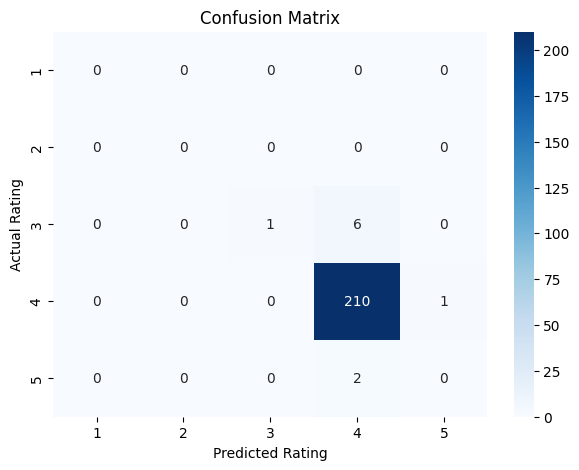

In [18]:
cm = confusion_matrix(
    y_actual_stars,
    y_pred_stars,
    labels=[1, 2, 3, 4, 5]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5]
)

plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.title("Confusion Matrix")
plt.show()

In [20]:
def predict_rating(
    review,
    category="Unknown",
    discounted_price=None,
    actual_price=None,
    discount_percentage=None,
    product_name="",
    about_product=""
):
    # Prepare text in the same format used during training
    combined_text = clean_text(
        review + " " + product_name + " " + about_product
    )

    # Use training-set medians for unspecified numeric features
    supplied = {
        "discounted_price": discounted_price,
        "actual_price": actual_price,
        "discount_percentage": discount_percentage
    }

    feature_values = []

    for col in numeric_cols:
        value = supplied.get(col)

        if value is None:
            value = medians[numeric_cols.index(col)]

        feature_values.append(float(value))

    # Apply the already-fitted scaler
    numeric_array = np.array(
        feature_values, dtype="float32"
    ).reshape(1, -1)

    numeric_scaled = scaler.transform(numeric_array).astype("float32")

    # Predict rating
    prediction = model.predict(
        {
            "review": tf.constant([combined_text], dtype=tf.string),
            "numeric": tf.constant(numeric_scaled, dtype=tf.float32),
            "category": tf.constant([category], dtype=tf.string)
        },
        verbose=0
    )[0, 0]

    prediction = float(np.clip(prediction, 1, 5))
    stars = int(np.clip(np.rint(prediction), 1, 5))

    print("Review:", review)
    print("Category:", category)
    print(f"Predicted rating: {prediction:.2f} / 5")
    print(f"Predicted whole-star rating: {stars} / 5")

    return prediction


# Example 1: Positive review
predict_rating(
    review="Excellent product, great quality, easy to use and worth the money.",
    category="Electronics",
    discounted_price=999,
    actual_price=1499,
    discount_percentage=33,
    product_name="Wireless headphones"
)

print("\n" + "-" * 50 + "\n")

# Example 2: Negative review
predict_rating(
    review="Poor quality. The product stopped working after two days.",
    category="Electronics",
    discounted_price=999,
    actual_price=1499,
    discount_percentage=33,
    product_name="Wireless headphones"
)

Review: Excellent product, great quality, easy to use and worth the money.
Category: Electronics
Predicted rating: 3.56 / 5
Predicted whole-star rating: 4 / 5

--------------------------------------------------

Review: Poor quality. The product stopped working after two days.
Category: Electronics
Predicted rating: 2.91 / 5
Predicted whole-star rating: 3 / 5


2.9065139293670654